In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import trackpy

df = pd.read_csv('/Users/rayyan/Desktop/honors_indep_study/Data/linked result.csv')
df = df[['particle_id', 'x', 'y', 'Area', 'frame']]   # drops the leftover unnamed index column

print(df.shape)
print(df['frame'].min(), df['frame'].max())
df.head()

(1102382, 5)
1 401


,particle_id,x,y,Area,frame
0,0,8.605,3.263,76,1
1,0,7.114,3.057,70,2
2,0,6.536,2.464,55,3
3,0,4.585,3.093,59,4
4,0,3.760,4.623,73,5


In [2]:
clus = trackpy.static.cluster(df, 24)   # same 24 px threshold as before, no size filter
print(clus.shape)
clus.head()

(1102382, 7)


,particle_id,x,y,Area,frame,cluster,cluster_size
0,0,8.605,3.263,76,1,0,1
8,1,782.011,1010.800,90,1,1,1
22,2,426.450,1012.742,120,1,2,6
423,3,119.818,1014.609,110,1,270,28
824,4,447.027,1013.581,74,1,2,6


cluster_size
1     145647
2      39779
3      23978
4      15508
5      11301
       ...  
94         1
95         2
96         1
97         1
99         1
Name: count, Length: 92, dtype: int64


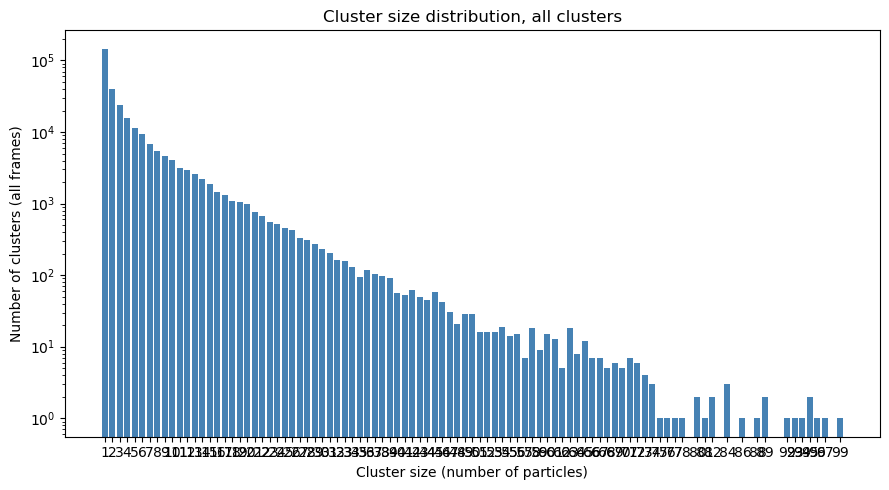

In [3]:
# one row per cluster per frame, so a 5-particle cluster is counted once, not 5 times
clusters = clus.drop_duplicates(['frame', 'cluster'])
size_counts = clusters['cluster_size'].value_counts().sort_index()
print(size_counts)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(size_counts.index, size_counts.values, color='steelblue')
ax.set_yscale('log')
ax.set_xlabel('Cluster size (number of particles)')
ax.set_ylabel('Number of clusters (all frames)')
ax.set_title('Cluster size distribution, all clusters')
ax.set_xticks(size_counts.index)
plt.tight_layout()
plt.savefig('week5_cluster_size_distribution.png', dpi=200)
plt.show()

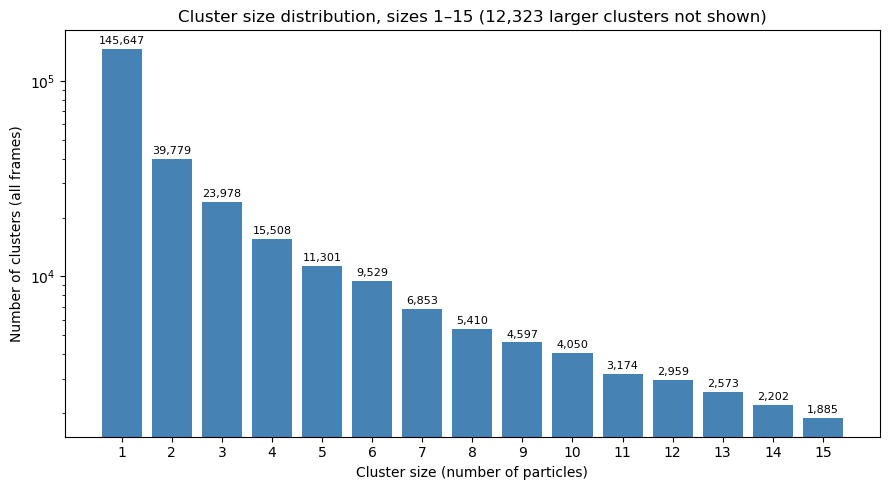

In [4]:
MAX_SIZE = 15
small = size_counts[size_counts.index <= MAX_SIZE]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(small.index, small.values, color='steelblue')
ax.bar_label(bars, labels=[f'{v:,}' for v in small.values], fontsize=8, padding=2)

ax.set_yscale('log')
ax.set_xticks(small.index)
ax.set_xlabel('Cluster size (number of particles)')
ax.set_ylabel('Number of clusters (all frames)')
ax.set_title(f'Cluster size distribution, sizes 1–{MAX_SIZE} '
             f'({size_counts[size_counts.index > MAX_SIZE].sum():,} larger clusters not shown)')
plt.tight_layout()
plt.savefig('week5_cluster_size_distribution.png', dpi=200)
plt.show()

In [5]:
SIZE = 3
c3 = clus[clus['cluster_size'] == SIZE].copy()

print(len(c3), "rows")                                        # should be 3 × 23,978 = 71,934
print(c3.drop_duplicates(['frame', 'cluster']).shape[0], "clusters")  # should be 23,978
c3.head()

71934 rows
23978 clusters


,particle_id,x,y,Area,frame,cluster,cluster_size
27092,96,250.041,970.968,111,1,96,3
29783,104,540.527,968.164,110,1,104,3
33574,115,1123.557,960.967,122,1,115,3
40215,139,259.167,988.894,66,1,96,3
45279,153,559.817,978.098,82,1,104,3


In [6]:
members = (c3.groupby(['frame', 'cluster'])['particle_id']
             .apply(frozenset)
             .reset_index(name='members'))
members.head()

,frame,cluster,members
0,1,96,"(96, 139, 163)"
1,1,104,"(104, 153, 155)"
2,1,115,"(115, 156, 158)"
3,1,311,"(332, 277, 311)"
4,1,397,"(633, 397, 645)"


In [7]:
members = members.sort_values(['frame', 'cluster']).reset_index(drop=True)
members['track_id'] = -1

prev = {}          # last frame's notebook: members (frozenset) -> track_id
next_id = 0        # next unused track_id
last_frame = None

for frame, rows in members.groupby('frame'):
    # if the previous frame had no size-3 clusters, there is nothing to continue from
    if last_frame is None or frame != last_frame + 1:
        prev = {}

    current = {}
    for idx, m in zip(rows.index, rows['members']):
        if m in prev:              # exact same 3 particles as last frame -> same cluster
            tid = prev[m]
        else:                      # any change -> new cluster
            tid = next_id
            next_id += 1
        members.at[idx, 'track_id'] = tid
        current[m] = tid

    prev = current                 # throw away the old notebook
    last_frame = frame

print(next_id, "tracked clusters")
members.head(10)

4789 tracked clusters


,frame,cluster,members,track_id
0,1,96,"(96, 139, 163)",0
1,1,104,"(104, 153, 155)",1
2,1,115,"(115, 156, 158)",2
3,1,311,"(332, 277, 311)",3
4,1,397,"(633, 397, 645)",4
5,1,425,"(616, 425, 519)",5
6,1,462,"(1382, 462, 486)",6
7,1,520,"(520, 558, 543)",7
8,1,532,"(586, 532, 604)",8
9,1,540,"(553, 540, 687)",9


In [8]:
life = members.groupby('track_id')['frame'].agg(['min', 'max', 'count'])
life['length'] = life['count']

print("every track covers frames with no gaps:", (life['max'] - life['min'] + 1 == life['count']).all())
print("no track appears twice in one frame:", not members.duplicated(['frame', 'track_id']).any())
print(life['length'].describe())
print(life['length'].value_counts().sort_index().head(15))

every track covers frames with no gaps: True
no track appears twice in one frame: True
count    4789.000000
mean        5.006891
std         6.636693
min         1.000000
25%         1.000000
50%         3.000000
75%         6.000000
max       114.000000
Name: length, dtype: float64
length
1     1576
2      702
3      512
4      369
5      307
6      204
7      179
8      160
9      112
10      84
11      84
12      59
13      56
14      40
15      61
Name: count, dtype: int64


track 1539 lasts 114 frames: 133 to 246
members: [np.int64(509), np.int64(609), np.int64(680)]


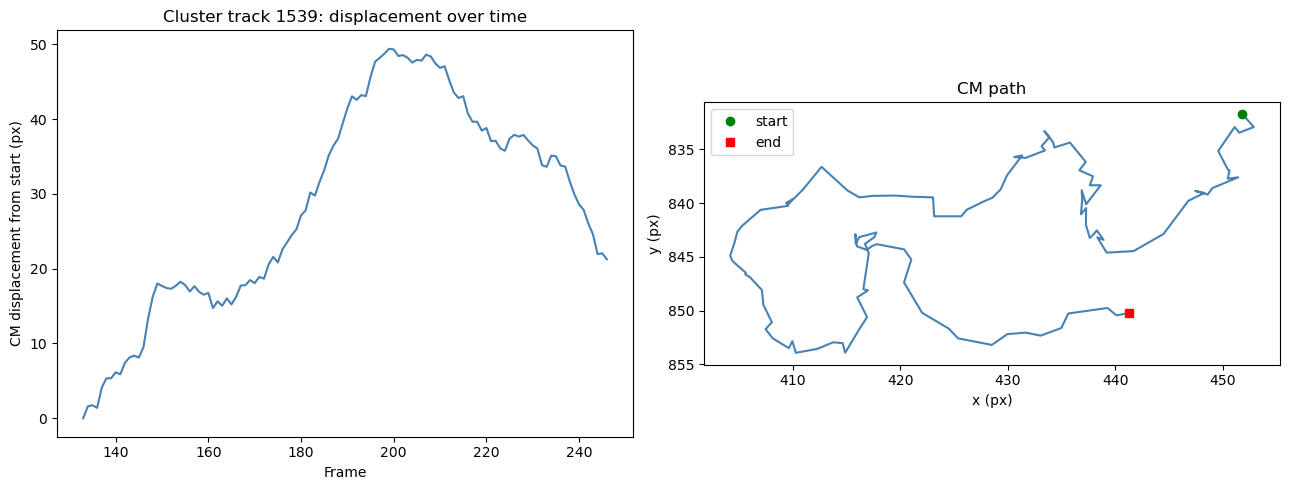

In [9]:
# give every particle row its track_id
c3 = c3.merge(members[['frame', 'cluster', 'track_id']], on=['frame', 'cluster'], how='left')

# pick the longest-lived cluster
TID = life['length'].idxmax()
one = c3[c3['track_id'] == TID]
print("track", TID, "lasts", life.loc[TID, 'length'], "frames:",
      life.loc[TID, 'min'], "to", life.loc[TID, 'max'])
print("members:", sorted(one['particle_id'].unique()))

# center of mass in each frame
cm = one.groupby('frame')[['x', 'y']].mean().rename(columns={'x': 'cm_x', 'y': 'cm_y'})

# displacement from where the cluster started
cm['disp_px'] = np.sqrt((cm['cm_x'] - cm['cm_x'].iloc[0])**2 +
                        (cm['cm_y'] - cm['cm_y'].iloc[0])**2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(cm.index, cm['disp_px'], color='steelblue')
ax1.set_xlabel('Frame')
ax1.set_ylabel('CM displacement from start (px)')
ax1.set_title(f'Cluster track {TID}: displacement over time')

ax2.plot(cm['cm_x'], cm['cm_y'], color='steelblue')
ax2.plot(cm['cm_x'].iloc[0], cm['cm_y'].iloc[0], 'o', color='green', label='start')
ax2.plot(cm['cm_x'].iloc[-1], cm['cm_y'].iloc[-1], 's', color='red', label='end')
ax2.invert_yaxis()                     # image coordinates: y runs downward
ax2.set_aspect('equal')
ax2.set_xlabel('x (px)'); ax2.set_ylabel('y (px)')
ax2.set_title('CM path')
ax2.legend()

plt.tight_layout()
plt.savefig('week5_cluster_CM_displacement.png', dpi=200)
plt.show()

In [10]:
c3.to_csv('/Users/rayyan/Desktop/honors_indep_study/Results/Clustering_Results_week5_tracked_size3.csv', index=False)